In [1]:
# INSTALACION DE LIBRERIAS

# TensorFlow será utilizado para entrenar el modelo
# de clasificación visual.
#
# Matplotlib y Seaborn permitirán visualizar imágenes
# y métricas del modelo.


!pip install tensorflow matplotlib seaborn scikit-learn

In [3]:
# Importar librerias

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (classification_report,confusion_matrix)
print("TensorFlow:",tf.__version__)

TensorFlow: 2.21.0


In [4]:
# DESCOMPRIMIR DATASET

# El dataset fue cargado como archivo ZIP.
#
# Se extraen todas las carpetas para que TensorFlow
# pueda acceder a las imágenes.


!unzip dataset_imagenes.zip

Archive:  dataset_imagenes.zip
   creating: dataset_imagenes/
   creating: dataset_imagenes/bebidas/
  inflating: dataset_imagenes/bebidas/01a8f05b-192b-4911-bfa4-91ac74606145.f9657dc2379a0547f101cd4b85baed5d_resultado_resultado_resultado.jpg  
  inflating: dataset_imagenes/bebidas/03e40a81-a225-4009-8fee-2f7913b0fe53.485b21d704298d017f8e13b7f9a9749e_resultado_resultado_resultado.jpg  
  inflating: dataset_imagenes/bebidas/04829933-ebac-414b-b205-7adfe9a3aa3c.632836e5acf15d7e8cfd45cbb0b7fa9a_resultado_resultado_resultado.jpg  
  inflating: dataset_imagenes/bebidas/0a06c569-ad49-406d-845c-5fd81401afd0.62a3e425ca31e4bd239ca5d879a8bbbc_resultado_resultado_resultado.jpg  
  inflating: dataset_imagenes/bebidas/0a611a5f-39e7-475d-ab9c-6e74bf18fa68.6078b58150d197ce6bc0cf4b0a921e5f_resultado_resultado_resultado.jpg  
  inflating: dataset_imagenes/bebidas/1160ad58-0775-4435-85f9-17a85bca079f.705797ceecf6f9749202671b1c8d290f_resultado_resultado_resultado.jpg  
  inflating: dataset_imagenes/bebid

In [5]:
# VERIFICAR ESTRUCTURA DEL DATASET

!find dataset_imagenes -type d

dataset_imagenes
dataset_imagenes/lacteos
dataset_imagenes/bebidas
dataset_imagenes/botanas


In [6]:
# CARGAR DATASET DE IMAGENES

# image_size = 224x224
# ResNet50 fue diseñada para trabajar con imágenes
# de este tamaño.
# validation_split = 20%
# 80% entrenamiento
# 20% validación

train_ds = tf.keras.utils.image_dataset_from_directory(

"dataset_imagenes",
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=(224,224),
    batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(

    "dataset_imagenes",
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(224,224),
    batch_size=32
)

Found 222 files belonging to 3 classes.
Using 178 files for training.
Found 222 files belonging to 3 classes.
Using 44 files for validation.


In [7]:
# CLASES DETECTADAS

print(
    train_ds.class_names
)

['bebidas', 'botanas', 'lacteos']


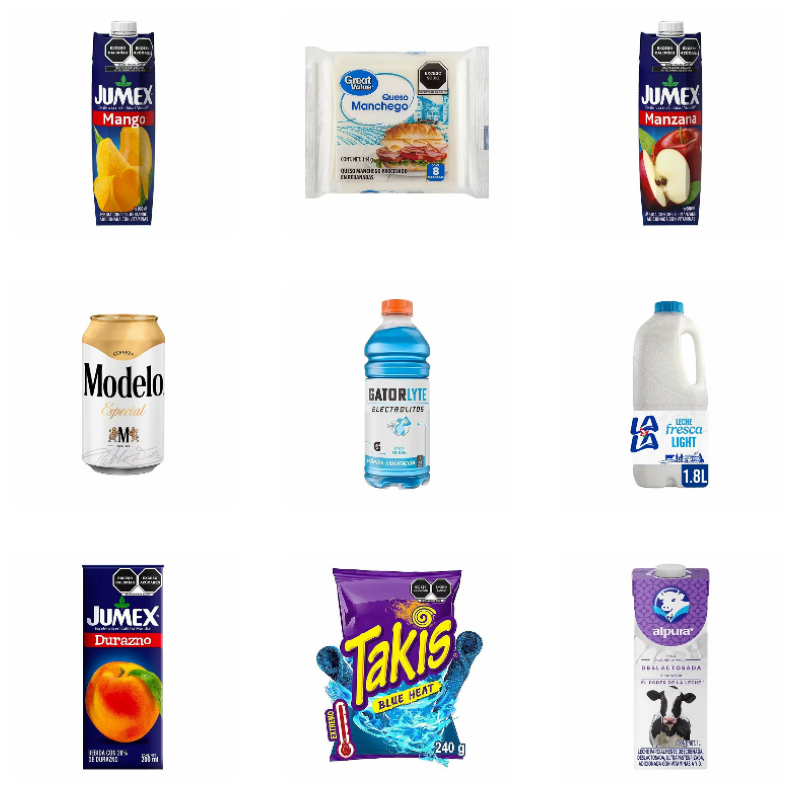

In [8]:
# VISUALIZAR IMAGENES DEL DATASET

plt.figure(figsize=(10,10))

for images, labels in train_ds.take(1):

    for i in range(9):

        ax = plt.subplot(
            3,
            3,
            i+1
        )

        plt.imshow(
            images[i]
            .numpy()
            .astype("uint8")
        )

        plt.axis("off")

In [9]:
# DATA AUGMENTATION

# Genera nuevas variaciones para mejorar la capacidad
# de generalización del modelo.


data_augmentation = tf.keras.Sequential([

    tf.keras.layers.RandomFlip(
        "horizontal"
    ),

    tf.keras.layers.RandomRotation(
        0.10
    ),

    tf.keras.layers.RandomZoom(
        0.10
    )

])

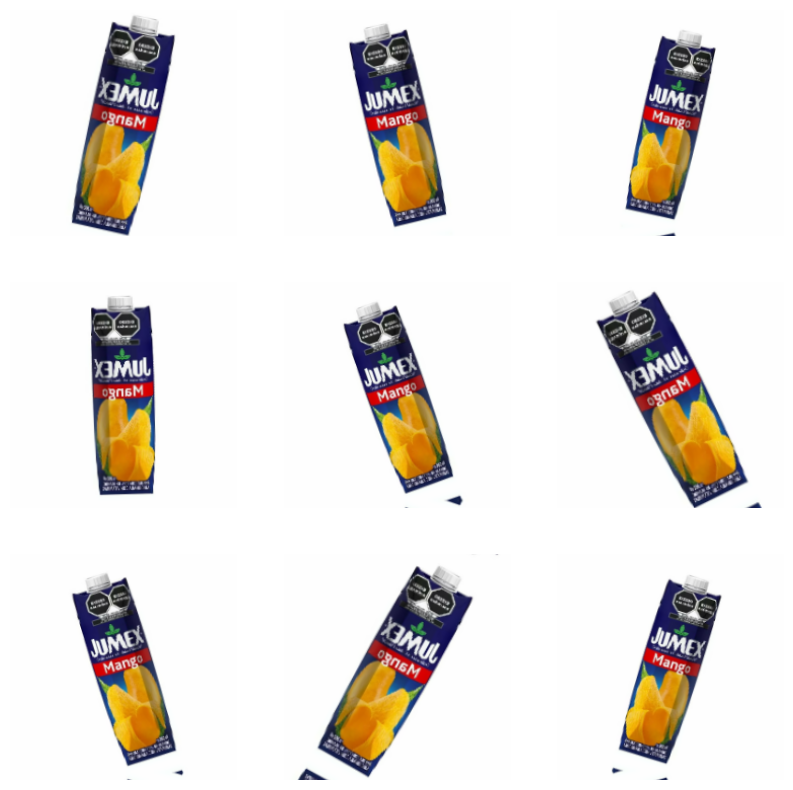

In [10]:
# VISUALIZAR DATA AUGMENTATION

plt.figure(figsize=(10,10))

for images, _ in train_ds.take(1):

    imagen = images[0]

    for i in range(9):

        ax = plt.subplot(
            3,
            3,
            i + 1
        )

        imagen_aug = data_augmentation(
            tf.expand_dims(
                imagen,
                0
            )
        )

        plt.imshow(
            imagen_aug[0]
            .numpy()
            .astype("uint8")
        )

        plt.axis("off")

In [11]:
# CARGA DEL MODELO RESNET50

# ResNet50 es una Red Neuronal Convolucional preentrenada
# con ImageNet (más de 1 millón de imágenes).
#
# No vamos a entrenar desde cero.
#
# Utilizaremos Transfer Learning para aprovechar
# conocimiento previamente adquirido.
#
# include_top=False
#
# Elimina la capa de clasificación original de ImageNet
# para que podamos adaptarla a nuestro problema.

base_model = tf.keras.applications.ResNet50(

    weights='imagenet',

    include_top=False,

    input_shape=(224,224,3)

)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [12]:
# TRANSFER LEARNING

# Se congelan las capas de ResNet50.
# De esta manera:
# Conservamos características aprendidas
# Reducimos tiempo de entrenamiento
# Evitamos sobreajuste

base_model.trainable = False

In [13]:
# ARQUITECTURA DEL MODELO

# Se agrega una nueva cabeza clasificadora.
# GlobalAveragePooling2D:
# Reduce la dimensionalidad de los mapas de activación.
# Dense:
# Aprende características específicas del problema.
# Softmax:
# Determina la probabilidad de cada clase.

modelo = tf.keras.Sequential([

    data_augmentation,

    tf.keras.layers.Rescaling(
        1./255
    ),

    base_model,

    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(
        128,
        activation='relu'
    ),

    tf.keras.layers.Dropout(
        0.30
    ),

    tf.keras.layers.Dense(
        3,
        activation='softmax'
    )

])

In [14]:
# MOSTRAR ARQUITECTURA

modelo.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (1, 7, 7, 2048)        │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (1, 2048)              │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (1, 128)               │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (1, 3)                 │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,371 (90.98 MB)

 Trainable params: 262,659 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [15]:
# CONFIGURACION DE ENTRENAMIENTO
# Adam:
# Optimizador moderno ampliamente utilizado.
# SparseCategoricalCrossentropy:
# Adecuado para múltiples categorías.
# Accuracy:
# Métrica principal de evaluación.

modelo.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [16]:
# ENTRENAMIENTO
# epochs=10
#
# Suficiente para observar el aprendizaje
# sin extender demasiado el tiempo.

historial = modelo.fit(train_ds,validation_data=val_ds,epochs=10)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 54s 8s/step - accuracy: 0.4157 - loss: 1.2686 - val_accuracy: 0.3864 - val_loss: 1.0767
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 79s 8s/step - accuracy: 0.4270 - loss: 1.1379 - val_accuracy: 0.3864 - val_loss: 1.0473
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 42s 7s/step - accuracy: 0.4382 - loss: 1.0811 - val_accuracy: 0.4773 - val_loss: 0.9957
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 83s 7s/step - accuracy: 0.5000 - loss: 0.9942 - val_accuracy: 0.5909 - val_loss: 0.9469
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 44s 8s/step - accuracy: 0.4944 - loss: 0.9950 - val_accuracy: 0.5909 - val_loss: 0.9282
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 83s 8s/step - accuracy: 0.4494 - loss: 1.0159 - val_accuracy: 0.5000 - val_loss: 0.9355
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 80s 8s/step - accuracy: 0.5112 - loss: 0.9875 - val_accuracy: 0.4545 - val_loss: 0.9210
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 43s 8s/step - accuracy: 0.5337 - loss: 0.9694 - val_accuracy: 0.5682 - val_loss: 0.9099
Epoch 9/

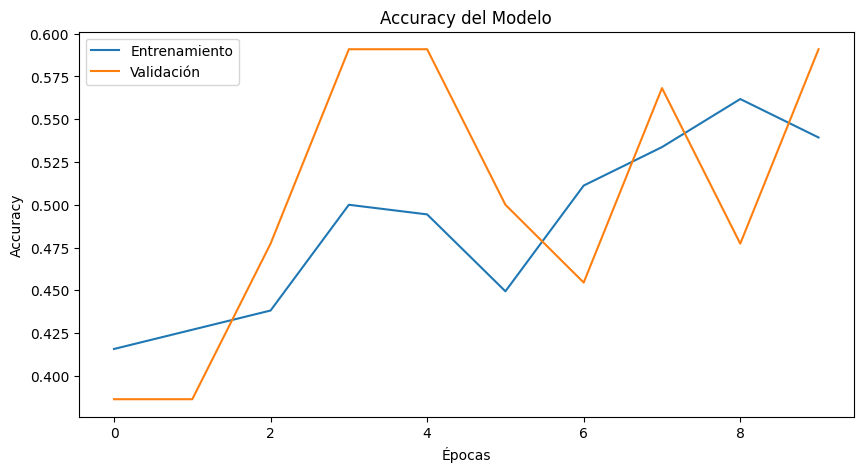

In [17]:
# GRAFICA DE ACCURACY

plt.figure(figsize=(10,5))

plt.plot(
    historial.history['accuracy'],
    label='Entrenamiento'
)

plt.plot(
    historial.history['val_accuracy'],
    label='Validación'
)

plt.title(
    'Accuracy del Modelo'
)

plt.xlabel(
    'Épocas'
)

plt.ylabel(
    'Accuracy'
)

plt.legend()

plt.show()

In [18]:
# EVALUACION DEL MODELO
# Se calcula la pérdida y accuracy sobre
# el conjunto de validación.


loss, accuracy = modelo.evaluate(val_ds)

print(f"Accuracy final: {accuracy:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step - accuracy: 0.5909 - loss: 0.8843
Accuracy final: 0.5909


In [19]:
# GENERAR PREDICCIONES

y_true = []

y_pred = []

for images, labels in val_ds:

    predicciones = modelo.predict(
        images
    )

    y_true.extend(
        labels.numpy()
    )

    y_pred.extend(
        np.argmax(
            predicciones,
            axis=1
        )
    )

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step


In [20]:
# PRECISION
# RECALL
# F1 SCORE

print(classification_report(y_true,y_pred,target_names=train_ds.class_names))

              precision    recall  f1-score   support

     bebidas       0.56      0.64      0.60        14
     botanas       0.67      0.50      0.57        12
     lacteos       0.58      0.61      0.59        18

    accuracy                           0.59        44
   macro avg       0.60      0.58      0.59        44
weighted avg       0.60      0.59      0.59        44



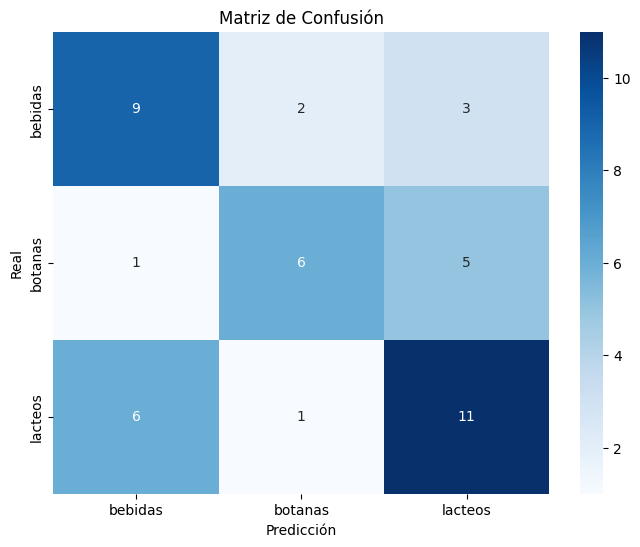

In [21]:
# MATRIZ DE CONFUSION

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(
    figsize=(8,6)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=
    train_ds.class_names,
    yticklabels=
    train_ds.class_names
)
plt.title("Matriz de Confusión")
plt.xlabel("Predicción")
plt.ylabel("Real")

plt.show()

In [22]:
# GUARDAR MODELO RESNET50

modelo.save("modelo_resnet50.keras")
print("Modelo guardado.")

Modelo guardado.


In [23]:
# FINE TUNING

# Se descongelan únicamente las últimas capas
# de ResNet50.
#
# Esto ayuda a que el modelo adapte parte del
# conocimiento adquirido en ImageNet a las
# categorías específicas del proyecto:
#
# - Bebidas
# - Botanas
# - Lácteos
#
# Las capas iniciales permanecen congeladas para
# conservar características visuales generales.


base_model.trainable = True

for layer in base_model.layers[:-20]:

    layer.trainable = False

In [24]:
# RECOMPILAR MODELO

modelo.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss='sparse_categorical_crossentropy',

    metrics=['accuracy']

)

In [25]:
# FINE TUNING

historial_ft = modelo.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 74s 11s/step - accuracy: 0.5955 - loss: 0.9019 - val_accuracy: 0.5000 - val_loss: 0.9156
Epoch 2/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 76s 9s/step - accuracy: 0.7640 - loss: 0.6326 - val_accuracy: 0.4773 - val_loss: 1.0111
Epoch 3/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 55s 9s/step - accuracy: 0.7809 - loss: 0.5511 - val_accuracy: 0.5000 - val_loss: 1.0272
Epoch 4/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 81s 9s/step - accuracy: 0.8764 - loss: 0.3885 - val_accuracy: 0.5000 - val_loss: 1.0471
Epoch 5/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 55s 10s/step - accuracy: 0.8652 - loss: 0.3788 - val_accuracy: 0.4545 - val_loss: 1.2613
Epoch 6/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 52s 9s/step - accuracy: 0.8820 - loss: 0.3425 - val_accuracy: 0.4318 - val_loss: 1.3110
Epoch 7/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 53s 9s/step - accuracy: 0.8933 - loss: 0.2750 - val_accuracy: 0.4773 - val_loss: 1.1488
Epoch 8/10
6/6 ━━━━━━━━━━━━━━━━━━━━ 54s 9s/step - accuracy: 0.8708 - loss: 0.3146 - val_accuracy: 0.4091 - val_loss: 1.2117
Epoch 

dataset_imagenes/lacteos/Carnation.jpg


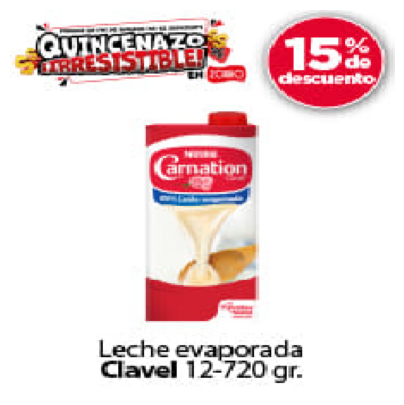

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step

Clase detectada:
bebidas

Probabilidades:
bebidas: 71.40%
botanas: 0.62%
lacteos: 27.98%


'bebidas'

In [29]:
import os

for raiz, carpetas, archivos in os.walk("dataset_imagenes"):
    for archivo in archivos:
        if "Carnation" in archivo:
            print(os.path.join(raiz, archivo))
clasificar_producto(
    "dataset_imagenes/lacteos/Carnation.jpg"
)

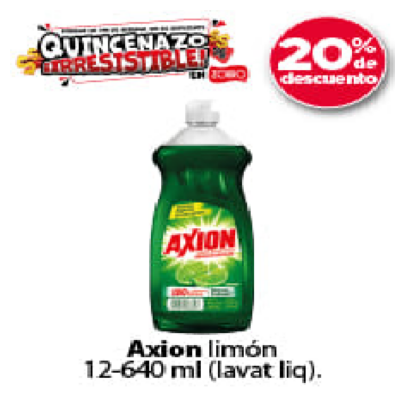

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 437ms/step

Clase detectada:
bebidas

Probabilidades:
bebidas: 71.40%
botanas: 0.62%
lacteos: 27.98%


'bebidas'

In [30]:
clasificar_producto(
    "dataset_imagenes/bebidas/Axion-4-de-Nov-2026.jpg"
)

In [ ]:
# =====================================================
# GUARDAR MODELO VISUAL
# =====================================================

modelo.save(
    "modelo_resnet50.keras"
)

print(
    "Modelo visual guardado correctamente."
)

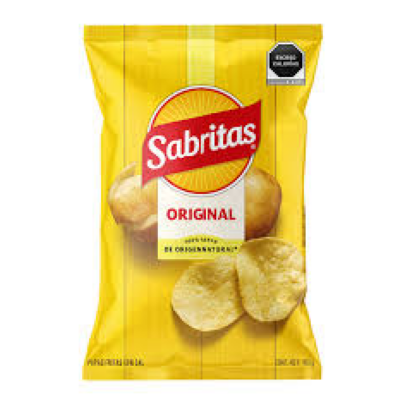

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step

Clase detectada:
bebidas

Probabilidades:
bebidas: 71.40%
botanas: 0.62%
lacteos: 27.98%


'bebidas'

In [32]:
clasificar_producto(
    "dataset_imagenes/botanas/sabritas.jpg"
)

In [33]:
# GUARDAR MODELO VISUAL

modelo.save(
    "modelo_resnet50.keras"
)

print(
    "Modelo visual guardado correctamente."
)

Modelo visual guardado correctamente.


In [34]:
from google.colab import files

files.download(
    "modelo_resnet50.keras"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>